# Titanic — Clean, Explore & Engineer

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

df = pd.read_csv("Titanic-Dataset.csv")
print(df.shape)
df.head()

(891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 1. Data Cleaning
### Missing values

In [2]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [3]:
# Cabin is ~77% missing -> drop it
df = df.drop(columns="Cabin")

# Impute: categorical -> mode | numerical skewed -> median | numerical normal -> mean
for col in df.columns[df.isnull().any()]:
    if not pd.api.types.is_numeric_dtype(df[col]):
        df[col] = df[col].fillna(df[col].mode()[0])
        print(f"{col}: categorical -> mode")
    else:
        skew = df[col].skew()
        if abs(skew) > 0.5:
            df[col] = df[col].fillna(df[col].median())
            print(f"{col}: skew={skew:.2f} -> median")
        else:
            df[col] = df[col].fillna(df[col].mean())
            print(f"{col}: skew={skew:.2f} -> mean")

df.isnull().sum()

Age: skew=0.39 -> mean
Embarked: categorical -> mode


PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64

### Duplicates

In [4]:
print("Duplicates:", df.duplicated().sum())
df = df.drop_duplicates()

Duplicates: 0


### Outliers

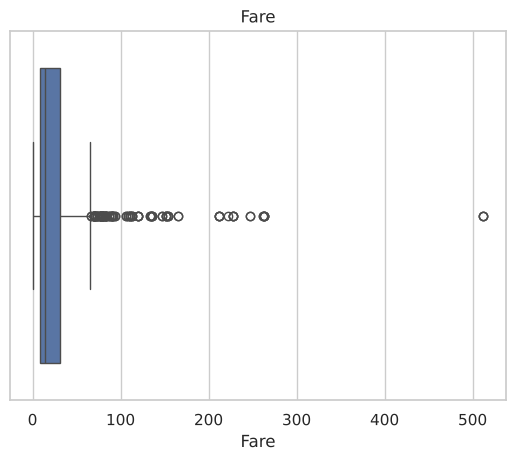

In [5]:
sns.boxplot(x=df["Fare"])
plt.title("Fare"); plt.show()

# Fare is heavily right-skewed; cap extreme values at the 99th percentile
df["Fare"] = df["Fare"].clip(upper=df["Fare"].quantile(0.99))

## 2. Feature Engineering

In [6]:
# FamilySize and IsAlone
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
df["IsAlone"] = (df["FamilySize"] == 1).astype(int)

# Title from Name
df["Title"] = df["Name"].str.extract(r",\s*([^\.]+)\.")[0]
df["Title"] = df["Title"].replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})
df.loc[~df["Title"].isin(["Mr", "Mrs", "Miss", "Master"]), "Title"] = "Rare"

df[["FamilySize", "IsAlone", "Title"]].head()

,FamilySize,IsAlone,Title
0,2,0,Mr
1,2,0,Mrs
2,1,1,Miss
3,2,0,Mrs
4,1,1,Mr


## 3. EDA

### Chart 1 — Age distribution

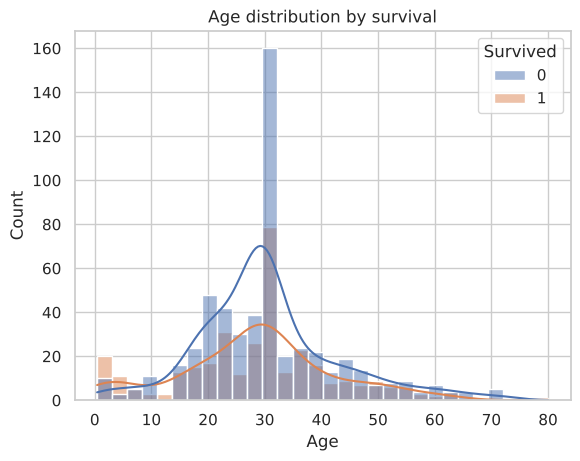

In [7]:
sns.histplot(data=df, x="Age", hue="Survived", bins=30, kde=True)
plt.title("Age distribution by survival"); plt.show()

### Chart 2 — Survival by Sex and Class

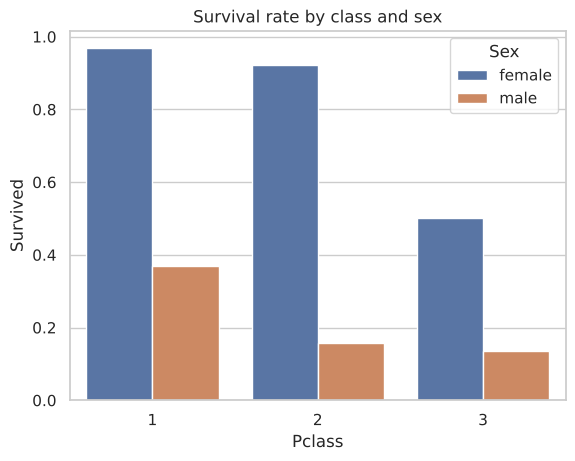

In [8]:
sns.barplot(data=df, x="Pclass", y="Survived", hue="Sex", errorbar=None)
plt.title("Survival rate by class and sex"); plt.show()

### Chart 3 — Fare by Class

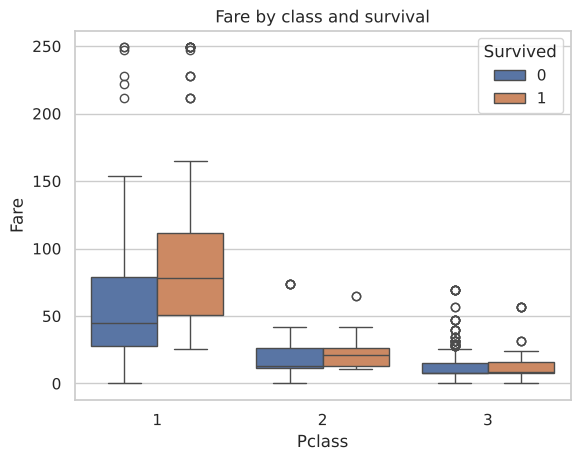

In [9]:
sns.boxplot(data=df, x="Pclass", y="Fare", hue="Survived")
plt.title("Fare by class and survival"); plt.show()

### Chart 4 — Correlation heatmap

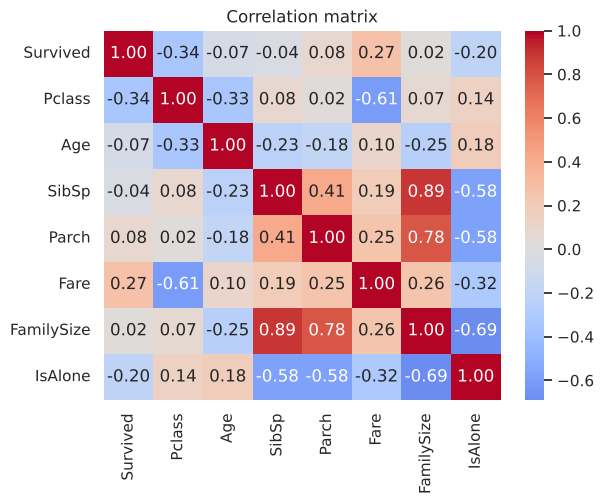

In [10]:
num = df.select_dtypes("number").drop(columns="PassengerId")
sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix"); plt.show()

### Chart 5 — Survival by Title and FamilySize

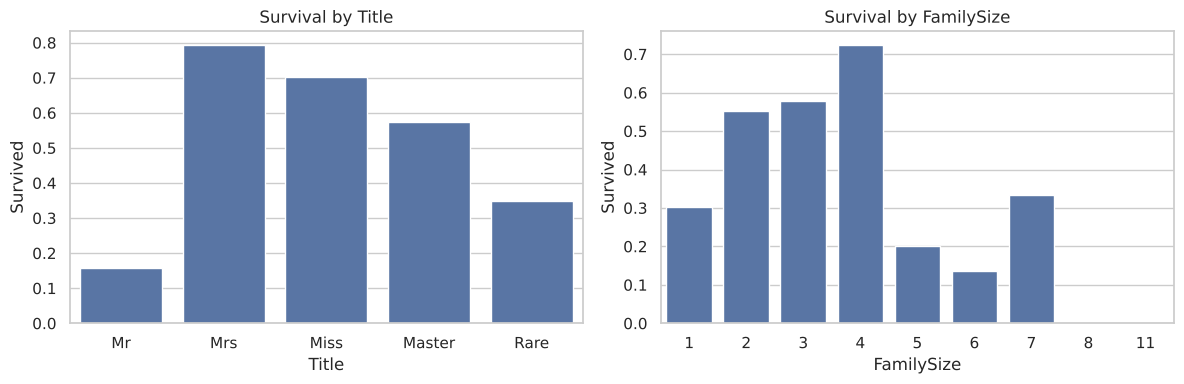

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(data=df, x="Title", y="Survived", errorbar=None, ax=axes[0])
sns.barplot(data=df, x="FamilySize", y="Survived", errorbar=None, ax=axes[1])
axes[0].set_title("Survival by Title"); axes[1].set_title("Survival by FamilySize")
plt.tight_layout(); plt.show()

## 4. Key Insights

1. **Sex is the strongest predictor.** 74% of women survived vs 19% of men (correlation ≈ −0.54 with being male).
2. **Class matters within sex.** 1st/2nd-class women survived at 97%/92%, while 3rd-class women survived at only 50%.
3. **Higher fare, higher survival.** Fare correlates positively with survival; 1st-class passengers paid far more and survived more.
4. **Title shows "children first".** Boys ("Master") survived at 58% vs 16% for adult men ("Mr").
5. **Family size is non-linear.** Solo travellers survived at 30%, small families (2–4) at 55–72%, and large families (5+) did much worse.